In [1]:
import math
import os
import numpy as np
import matplotlib.pyplot as plt

class UniformRNG:
    def __init__(self, seed=123):
        self.state = seed
        self.a = 6364136223846793005
        self.c = 1442695040888963407
        self.m = 2 ** 64

    def uniform(self):
        self.state = (self.a * self.state + self.c) % self.m
        return ((self.state >> 11) + 0.5) / 2 ** 53

    def shuffle_order(self, n):
        order = list(range(n))
        for i in range(n - 1, 0, -1):
            j = int(self.uniform() * (i + 1))
            order[i], order[j] = order[j], order[i]
        return order

rng = UniformRNG(seed=42)
os.makedirs("figures", exist_ok=True)

In [2]:
n = 6000
K = 3
weights = [0.25, 0.35, 0.40]

means = [[-4.0, 2.0], [2.0, 5.0], [5.0, -3.0]]
means_2 = means + np.array([[3.0, -2.0]])
class_means = [means, means_2]

covariances = [
    [[0.5, 0.0], [0.0, 3.0]],       # Wide Vertical
    [[2.5, 1.2], [1.2, 1.5]],       # Full (+tilt)
    [[2.0, -1.0], [-1.0, 2.5]],     # Full (-tilt)
]

covariances_2 = [
    [[0.8, 0.0], [0.0, 0.8]],       # Isotropic (Small)
    [[1.5, 0.0], [0.0, 1.5]],       # Isotropic (Medium)
    [[3.0, 0.0], [0.0, 3.0]],       # Isotropic (Large)
]

class_covariances = [covariances, covariances_2]

covariance_names = [
    ["Wide Vertical", "Full (+tilt)", "Full (-tilt)"],
    ["Isotropic (Small)", "Isotropic (Medium)", "Isotropic (Large)"],
]

In [3]:
def standard_normal():
    u1 = rng.uniform()
    while u1 == 0:
        u1 = rng.uniform()
    u2 = rng.uniform()
    radius = math.sqrt(-2 * math.log(u1))
    return radius * math.cos(2 * math.pi * u2), radius * math.sin(2 * math.pi * u2)


def generate_gmm(n, weights, means, covariances):
    stds, vectors = [], []
    for C in covariances:
        eigenvalues, eigenvectors = np.linalg.eigh(np.asarray(C, dtype=float))
        stds.append(np.sqrt(eigenvalues))
        vectors.append(eigenvectors)

    points, labels = [], []
    for _ in range(n):
        u = rng.uniform()
        if u < weights[0]:
            k = 0
        elif u < weights[0] + weights[1]:
            k = 1
        else:
            k = 2

        z = np.array(standard_normal())
        points.append(np.asarray(means[k]) + vectors[k] @ (stds[k] * z))
        labels.append(k)
    return np.array(points), np.array(labels)

In [4]:

class_samples = []
class_component_labels = []

for class_index in range(2):
    X, labels = generate_gmm(n, weights, class_means[class_index],
                               class_covariances[class_index])
    class_samples.append(X)
    class_component_labels.append(labels)

print([sample.shape for sample in class_samples])

[(6000, 2), (6000, 2)]


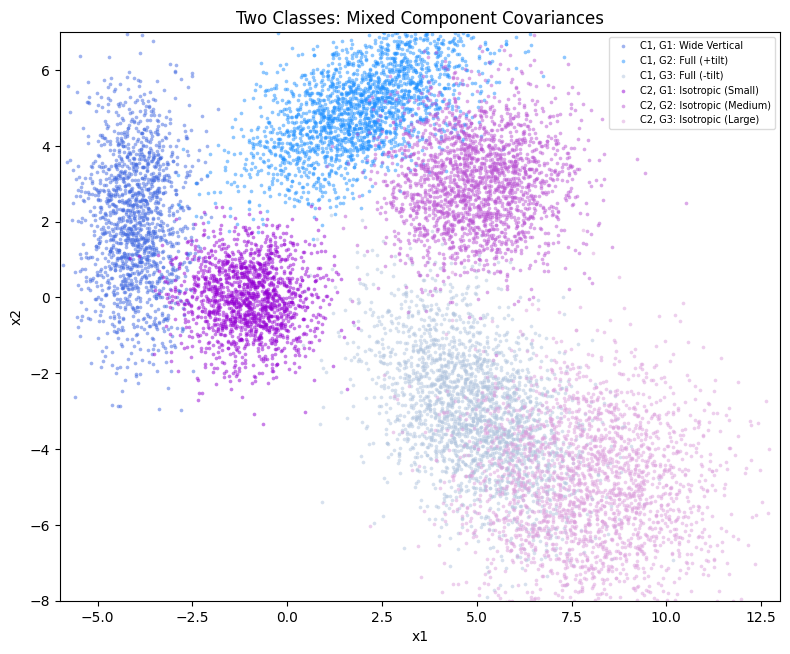

In [5]:
component_colors = [
    ["royalblue", "dodgerblue", "lightsteelblue"],
    ["darkviolet", "mediumorchid", "plum"]
]

plt.figure(figsize=(8, 7))
for class_index in range(2):
    for k in range(K):
        sample = class_samples[class_index][class_component_labels[class_index] == k]
        plt.scatter(
            sample[:, 0], sample[:, 1], s=7, alpha=0.5, linewidths=0,
            color=component_colors[class_index][k],
            label=f"C{class_index + 1}, G{k + 1}: {covariance_names[class_index][k]}"
        )

plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Two Classes: Mixed Component Covariances")
plt.legend(fontsize=7, framealpha=0.7)
plt.axis("scaled")
plt.xlim(-6, 13)
plt.ylim(-8, 7)
plt.tight_layout()
plt.savefig("figures/generated_data.png", dpi=200)
plt.show()

In [6]:

train_class_samples = []
test_class_samples = []
train_end = int(0.8 * n)

for samples in class_samples:
    shuffled = samples[rng.shuffle_order(n)]
    train_class_samples.append(shuffled[:train_end])
    test_class_samples.append(shuffled[train_end:])

In [7]:
class KMeans:
    def __init__(self, K=3):
        self.K = K
        self.centers = None

    def distances(self, X):
        diff = X[:, None, :] - self.centers[None, :, :]
        return np.sum(diff ** 2, axis=2)

    def predict(self, X):
        return np.argmin(self.distances(X), axis=1)

    def distortion(self, X):
        return np.sum(np.min(self.distances(X), axis=1))

    def fit(self, X, max_iterations=100):
        self.centers = X[rng.shuffle_order(len(X))[:self.K]].astype(float)

        for _ in range(max_iterations):
            labels = self.predict(X)
            new_centers = self.centers.copy()
            for k in range(self.K):
                if np.any(labels == k):
                    new_centers[k] = X[labels == k].mean(axis=0)

            converged = np.max(np.abs(self.centers - new_centers)) < 1e-6
            self.centers = new_centers
            if converged:
                break
        return self

In [8]:
class_models = []

for class_index, samples in enumerate(train_class_samples):
    model = KMeans(K=K).fit(samples)
    class_models.append(model)
    print(f"Class {class_index + 1} centres:\n{model.centers}")
    print(f"Class {class_index + 1} training distortion: {model.distortion(samples):.2f}\n")

Class 1 centres:
[[-3.88340636  2.06231604]
 [ 4.99806848 -3.07608454]
 [ 2.08291468  5.03383021]]
Class 1 training distortion: 19037.66

Class 2 centres:
[[ 5.00369139  3.02721011]
 [-0.980321   -0.01073472]
 [ 8.0038942  -5.04532491]]
Class 2 training distortion: 18292.38



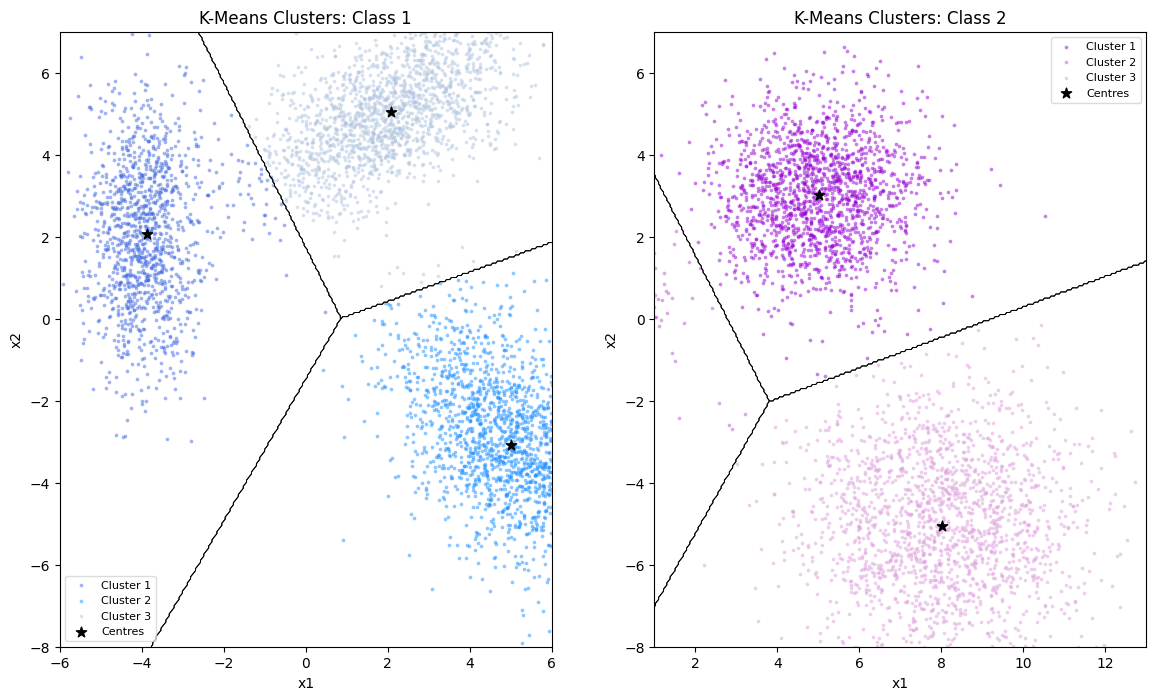

In [9]:
x_ranges = [(-6, 6), (1, 13)]
y_values = np.linspace(-8, 7, 300)

plt.figure(figsize=(12, 7))
for class_index, model in enumerate(class_models):
    samples = train_class_samples[class_index]
    labels = model.predict(samples)

    x_min, x_max = x_ranges[class_index]
    x_values = np.linspace(x_min, x_max, 300)
    x_grid, y_grid = np.meshgrid(x_values, y_values)
    grid_points = np.column_stack((x_grid.ravel(), y_grid.ravel()))
    grid_labels = model.predict(grid_points).reshape(x_grid.shape)

    plt.subplot(1, 2, class_index + 1)
    for k in range(K):
        cluster = samples[labels == k]
        plt.scatter(cluster[:, 0], cluster[:, 1], s=7, alpha=0.5, linewidths=0,
                    color=component_colors[class_index][k], label=f"Cluster {k + 1}")
        plt.contour(x_grid, y_grid, grid_labels == k, levels=[0.5],
                    colors="black", linewidths=0.7)

    plt.scatter(model.centers[:, 0], model.centers[:, 1],
                marker="*", s=60, color="black", label="Centres")
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title(f"K-Means Clusters: Class {class_index + 1}")
    plt.legend(fontsize=8, framealpha=0.7)
    plt.axis("scaled")
    plt.xlim(x_min, x_max)
    plt.ylim(-8, 7)

plt.tight_layout()
plt.savefig("figures/kmeans_clusters.png", dpi=200)
plt.show()

In [10]:
def class_distortions(X):
    return np.column_stack([np.min(model.distances(X), axis=1) for model in class_models])


confusion_matrix = np.zeros((2, 2), dtype=int)

for true_class, samples in enumerate(test_class_samples):
    predictions = np.argmin(class_distortions(samples), axis=1)
    for predicted_class in predictions:
        confusion_matrix[true_class, predicted_class] += 1

print("Confusion matrix:\n", confusion_matrix)
print("Accuracy:", np.trace(confusion_matrix) / confusion_matrix.sum())

Confusion matrix:
 [[1084  116]
 [ 115 1085]]
Accuracy: 0.90375


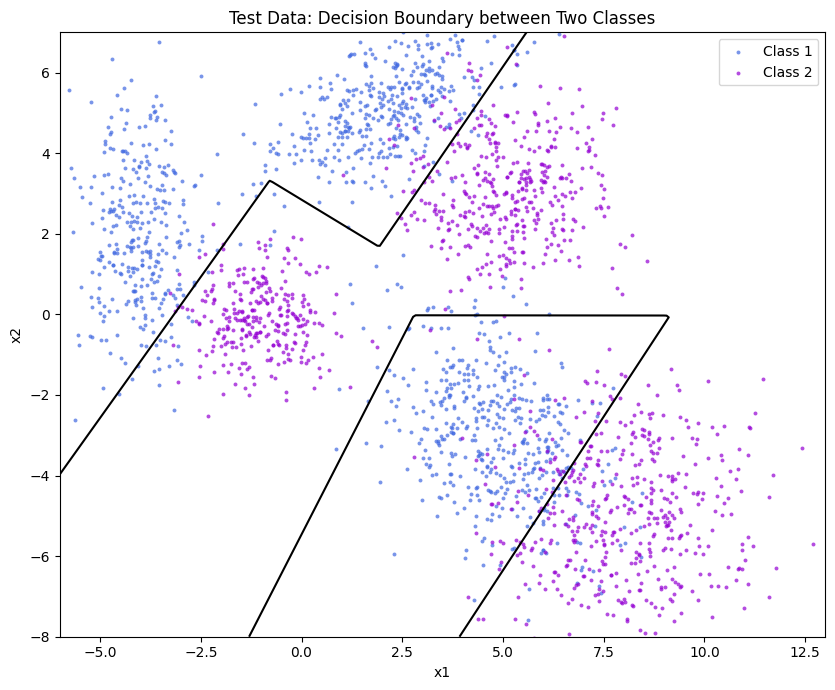

In [11]:
x_values = np.linspace(-6, 13, 300)
y_values = np.linspace(-8, 7, 300)
x_grid, y_grid = np.meshgrid(x_values, y_values)
grid_points = np.column_stack((x_grid.ravel(), y_grid.ravel()))

grid_distortions = class_distortions(grid_points)
difference = (grid_distortions[:, 0] - grid_distortions[:, 1]).reshape(x_grid.shape)

plt.figure(figsize=(9, 7))
for class_index, samples in enumerate(test_class_samples):
    plt.scatter(samples[:, 0], samples[:, 1], s=8, alpha=0.7, linewidths=0,
                color=component_colors[class_index][0], label=f"Class {class_index + 1}")

plt.contour(x_grid, y_grid, difference, levels=[0], colors="black")
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Test Data: Decision Boundary between Two Classes")
plt.legend(fontsize=10)
plt.axis("scaled")
plt.xlim(-6, 13)
plt.ylim(-8, 7)
plt.tight_layout()
plt.savefig("figures/decision_boundary.png", dpi=200)
plt.show()